# 04 · Híbrido y ensemble

**Grupo:** Oscar Romero Quincoces · Fernando Dapena Tauste · Daniel Garcia Lopez

**Objetivo.** El 02 aprendió cómo son las operaciones normales; el 03 aprendió a reconocer fraudes etiquetados. Aquí preguntamos si **dar sus scores de anomalía al XGBoost del 03 aporta información adicional**. El clasificador sigue siendo el mismo: solo cambian las columnas que recibe.

**Referencia a batir (03, D-2.5):** XGBoost de profundidad 3, con 400 árboles y sin reequilibrar las clases. Se reproduce con los datos y las versiones actuales; las cifras ejecutadas prevalecen sobre las conclusiones históricas de los notebooks anteriores.

| Modelo | Qué comprueba | Entrada |
|---|---|---|
| **XGBoost original** | La referencia del 03 | 22 variables |
| **XGBoost + score del GMM** | Si una señal de anomalía aporta algo | 22 variables + GMM del eje menor |
| **XGBoost + cinco scores del 02** | Si otras formas de rareza añaden información útil | 22 variables + GMM eje, LOF, ECOD, GMM completo y autoencoder |

La comparación principal mantiene **estos tres modelos**, sin promedios de predicciones. Después de §5 se añade una prueba exploratoria de prioridad de variables mediante `feature_weights` (§5.1), con sus propios resultados y control uniforme.

**Cómo leer este notebook.** Como el 01–03: **pregunta → tabla/figura → conclusión → impacto**. Los cinco folds externos son los mismos del 01. Los scores se recalculan **dentro de cada fold**, con validación cruzada interna para las filas que entrenan al híbrido. El test confirma una elección ya cerrada.

| Parte I · Construcción de los híbridos | Parte II · Comparación y entrega |
|---|---|
| 0. Setup | 6. ¿Qué modelo gana en CV? |
| 1. ¿Se reproduce el XGBoost del 03? | 7. ¿Recupera otros fraudes? |
| 2. ¿Qué información añaden los scores? | 8. ¿Qué modelo elegimos antes del test? |
| 3. ¿Cómo evitamos que la validación se filtre? | 9. ¿Se confirma en test? |
| 4. ¿Ayuda el score del GMM? | 10. ¿En qué se fija el híbrido? |
| 5. ¿Ayudan los cinco scores? | 11. Reentrenar y exportar producción |
| 5.1. ¿Ayuda dar prioridad a las variables más predictivas? | 12. Conclusiones |

**Resultado esperado del trabajo:** medir la aportación real de las nuevas columnas, conservar el modelo más sencillo si no mejoran de forma consistente y dejar el CSV final de producción.

In [1]:
# ============================================================
# CELDA COMÚN v2 — NO MODIFICAR (idéntica en 02, 03, 04 y 99)
# Lee el dataset preparado en 01: split fijo, folds por grupo y features. Ver D-0.1, D-1.1–D-1.4.
# Uso: m = fit(modelo, X_train, y_train); report("x", score(m, X_test)); cv_aupr(modelo); save_submission(score(m, X_prod))
# ============================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone, is_classifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.options.display.max_columns = None
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT / "data" / "output"
PREP_CSV = Path(os.environ.get("PREP_CSV", OUTPUT_DIR / "01_dataset_preparado.csv"))
if not PREP_CSV.exists():
    raise FileNotFoundError(f"No existe {PREP_CSV}: ejecuta antes notebooks/01_EDA_y_preprocesado.ipynb")

FEAT_RAW = [f"X{i}" for i in range(1, 21)] + ["Amount"]
df = pd.read_csv(PREP_CSV)
df[FEAT_RAW] = df[FEAT_RAW].astype(float)  # el CSV guarda X enteras: se leen como float, igual que los originales
df_const = df[df["split"] != "prod"].sort_values("row_id").reset_index(drop=True)
df_prod = df[df["split"] == "prod"].sort_values("row_id").reset_index(drop=True)
FEATURES = [f"X{i}" for i in range(1, 21)] + ["log1p_Amount", "amount_freq"]  # conjunto por defecto (D-1.2)

tr, te = df_const[df_const["split"] == "train"], df_const[df_const["split"] == "test"]
X_train, y_train, groups_train = tr[FEATURES], tr["Class"].astype(int), tr["group_id"]
X_test, y_test = te[FEATURES], te["Class"].astype(int)
X_prod = df_prod[FEATURES]
dup_test = te["dup_en_train"].to_numpy(bool)  # filas de test con copia exacta en train (D-1.1)
# Folds por grupo hechos en 01 → (idx_train, idx_val) posicionales sobre X_train; vale como cv= en sklearn
cv_splits = [(np.flatnonzero(tr["fold"].to_numpy() != k), np.flatnonzero(tr["fold"].to_numpy() == k)) for k in range(5)]

def make_pipe(model, scaler="standard"):
    """Escalador ('standard' | 'robust' | None) + modelo: el escalado se ajusta DENTRO de cada fold."""
    steps = {"standard": [StandardScaler()], "robust": [RobustScaler()], None: []}[scaler]
    return make_pipeline(*steps, model)

def score(model, X):
    """Mayor = más fraude. Clasificador: predict_proba[:, 1] (o decision_function). No supervisado: −score_samples."""
    if not is_classifier(model):
        return -model.score_samples(X)  # GMM: −log-verosimilitud; IF / OCSVM / LOF(novelty=True): −normalidad
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def fit(model, X, y):
    """Copia limpia ajustada: clasificador con (X, y); no supervisado SOLO con las normales (y == 0)."""
    y = np.asarray(y)
    return clone(model).fit(X, y) if is_classifier(model) else clone(model).fit(X[y == 0])

def metrics(y_true, scores):
    """Métrica oficial: AUPR (average_precision_score). Mayor score = más fraude."""
    return {"aupr": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores)}

def cv_aupr(model, X=X_train, y=y_train):
    """AUPR por fold sobre cv_splits (clasificadores y no supervisados). Devuelve (media, std, scores OOF alineados con X)."""
    X, y, oof, auprs = np.asarray(X, dtype=float), np.asarray(y), np.zeros(len(y)), []
    assert len(X) == len(tr), "X debe tener las filas de X_train en su orden"
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], y[it]), X[iv])
        auprs.append(average_precision_score(y[iv], oof[iv]))
    print(f"CV AUPR = {np.mean(auprs):.4f} ± {np.std(auprs):.4f}")
    return np.mean(auprs), np.std(auprs), oof

def report(name, s_test):
    """AUPR de test con y sin las filas duplicadas de train (D-1.1), y ROC-AUC."""
    s, y = np.asarray(s_test, dtype=float), y_test.to_numpy()
    assert len(s) == len(y), f"{len(s)} scores != {len(y)} filas de test"
    r = {"modelo": name, **metrics(y, s), "aupr_sin_dup": average_precision_score(y[~dup_test], s[~dup_test])}
    print(f"{name}: AUPR test={r['aupr']:.4f} | sin dup={r['aupr_sin_dup']:.4f} | ROC-AUC={r['roc_auc']:.4f}")
    return r

def plot_pr(y_true, scores_by_model, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for name, s in scores_by_model.items():
        p, r, _ = precision_recall_curve(y_true, s)
        ax.plot(r, p, label=f"{name} (AUPR={average_precision_score(y_true, s):.3f})")
    ax.axhline(np.mean(y_true), ls="--", c="grey", label="aleatorio")
    ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
    ax.legend()
    return ax

def save_submission(scores, name="scores_produccion"):
    """Entregable: CSV de UNA columna `score`, una fila por transacción de producción (mismo orden)."""
    scores = np.asarray(scores, dtype=float).ravel()
    assert len(scores) == len(df_prod) == 113_923, f"{len(scores)} scores, {len(df_prod)} filas de producción"
    assert np.isfinite(scores).all(), "hay scores no finitos"
    pd.DataFrame({"score": scores}).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

print(f"train {X_train.shape} fraudes={y_train.sum()} | test {X_test.shape} fraudes={y_test.sum()} "
      f"(dup={dup_test.sum()}) | prod {X_prod.shape} | folds={[len(v) for _, v in cv_splits]}")

train (119618, 22) fraudes=206 | test (51266, 22) fraudes=89 (dup=1643) | prod (113923, 22) | folds=[23924, 23924, 23923, 23924, 23923]


## 0. Setup

Librerías y utilidades propias de este notebook. Los datos, los cinco folds y `fit()`, `score()`, `report()`, `plot_pr()` y `save_submission()` vienen de la **celda común v2, sin modificar**. Se mantienen gris = normal, rojo = fraude y la familia de boosting en morado.

In [2]:
import copy
import hashlib
import json
import platform
import time
import warnings
import contextlib, io
import seaborn as sns
import scipy
import sklearn
import torch
from torch import nn
from scipy import stats
from sklearn.base import BaseEstimator, OutlierMixin, TransformerMixin
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor
from threadpoolctl import threadpool_limits
import xgboost as xgb
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (8, 4.5), "axes.titleweight": "bold"})
C = {0: "#9e9e9e", 1: "#d62728"}
LBL = {0: "normal", 1: "fraude"}
N_JOBS = os.cpu_count() or 2
NOMBRES = ["XGBoost original", "XGBoost + score del GMM", "XGBoost + cinco scores del 02"]
REF, UNO, CINCO = NOMBRES
COLORES = dict(zip(NOMBRES, ["#8172b3", "#dd8452", "#55a868"]))
SCORES = ["s02_gmm_eje", "s02_lof_4ejes", "s02_ecod_top4", "s02_gmm_full", "s02_ae12"]
EXTRAS = {REF: [], UNO: SCORES[:1], CINCO: SCORES}
XGB_FINAL = xgb.XGBClassifier(n_estimators=400, learning_rate=.05, max_depth=3,
                             subsample=.8, colsample_bytree=.7, n_jobs=N_JOBS, random_state=SEED)
VERSIONES = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "xgboost": xgb.__version__, "torch": torch.__version__}
CACHE_DIR = ROOT / ".cache" / "04_hibrido"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = CACHE_DIR / "figuras"
FIG_DIR.mkdir(exist_ok=True)

def mostrar_figura(nombre):
    plt.gcf().savefig(FIG_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()

RES, OOF = {}, {}
Xa, ya, ga = X_train.to_numpy(float), y_train.to_numpy(), groups_train.to_numpy()

def registrar(nombre, scores, segundos):
    scores = np.asarray(scores, float)
    assert scores.shape == ya.shape and np.isfinite(scores).all()
    a = np.array([average_precision_score(ya[iv], scores[iv]) for _, iv in cv_splits])
    RES[nombre] = {"familia": "boosting" if nombre == REF else "híbrido", "n_feats": len(FEATURES) + len(EXTRAS[nombre]),
                   "media": a.mean(), "std": a.std(), "segundos": segundos,
                   **{f"fold{k}": v for k, v in enumerate(a)}}
    OOF[nombre] = scores
    print(f"{nombre}: CV AUPR = {a.mean():.4f} ± {a.std():.4f} ({segundos:.1f} s)")

def tabla_cv():
    return pd.DataFrame(RES).T.rename_axis("modelo").sort_values("media", ascending=False)

def por_fold(nombre):
    return np.array([RES[nombre][f"fold{k}"] for k in range(5)])

def frente_a(nombres, referencia=REF):
    return pd.DataFrame({n: {"media": RES[n]["media"], "std": RES[n]["std"],
                             "Δ AUPR": (por_fold(n)-por_fold(referencia)).mean(),
                             "peor Δ fold": (por_fold(n)-por_fold(referencia)).min(),
                             "folds que gana (de 5)": int((por_fold(n)>por_fold(referencia)).sum())}
                         for n in nombres}).T

def plot_folds(nombres, title):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for k in range(5):
        ax.plot(range(len(nombres)), [RES[n][f"fold{k}"] for n in nombres], c="grey", lw=.8, alpha=.6, marker=".")
    for i, n in enumerate(nombres):
        ax.errorbar(i, RES[n]["media"], yerr=RES[n]["std"], fmt="o", ms=9, capsize=5, color=COLORES[n], zorder=3)
        ax.annotate(f"{RES[n]['media']:.3f}", (i, RES[n]["media"]), xytext=(9, 2), textcoords="offset points")
    ax.set_xticks(range(len(nombres)), nombres, rotation=12, ha="right")
    ax.set(ylabel="AUPR (CV)", title=title)
    fig.tight_layout()

pd.Series(VERSIONES, name="versión").to_frame()

,versión
python,3.13.7
numpy,2.3.3
pandas,2.3.2
scikit-learn,1.8.0
scipy,1.16.2
xgboost,3.2.0
torch,2.9.0+cpu


---
# PARTE I · CONSTRUCCIÓN DE LOS HÍBRIDOS

Primero se reproduce la referencia (§1) y se identifican los scores (§2). Después se construyen sin mezclar entrenamiento y validación (§3) y se prueban las dos ampliaciones del mismo XGBoost (§4–§5).

## 1. ¿Se reproduce el XGBoost del 03?

**Qué miramos y por qué.** Repetimos la configuración final del 03, sobre las mismas 22 variables y los mismos cinco folds. No se reajustan hiperparámetros ni pesos de clase. Esta ejecución, no una cifra escrita a mano, será la referencia para los híbridos. Se contrastan también los scores exportados por el 03: una diferencia se documenta, no se oculta.

In [3]:
t0, s_ref = time.time(), np.full(len(ya), np.nan)
for k, (it, iv) in enumerate(cv_splits):
    assert not np.intersect1d(ga[it], ga[iv]).size
    m = fit(XGB_FINAL, Xa[it], ya[it])
    s_ref[iv] = score(m, Xa[iv])
registrar(REF, s_ref, time.time()-t0)

claves = tr[["split", "row_id"]].reset_index(drop=True)
prev03 = pd.read_csv(OUTPUT_DIR / "03_scores.csv")
assert not prev03.duplicated(["split", "row_id"]).any()
prev_tr = claves.merge(prev03, on=["split", "row_id"], how="left", validate="one_to_one", sort=False)
assert prev_tr["s03_xgb_d3"].notna().all()
HIST03 = np.array([average_precision_score(ya[iv], prev_tr["s03_xgb_d3"].to_numpy()[iv]) for _, iv in cv_splits])
pd.DataFrame({"03 exportado": HIST03, "04 reproducido": por_fold(REF), "diferencia": por_fold(REF)-HIST03},
             index=[f"fold {k}" for k in range(5)]).round(6)

XGBoost original: CV AUPR = 0.8645 ± 0.0610 (5.1 s)


,03 exportado,04 reproducido,diferencia
fold 0,0.923533,0.933171,0.009638
fold 1,0.877567,0.891226,0.013659
fold 2,0.762011,0.762681,0.000670
fold 3,0.837628,0.830371,-0.007257
fold 4,0.905599,0.905059,-0.000540


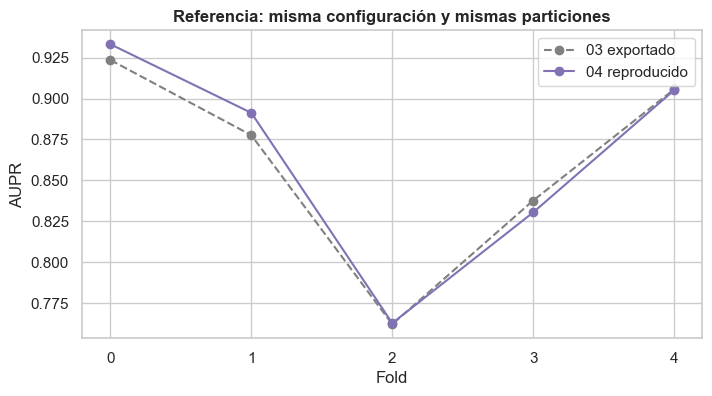

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(5), HIST03, "o--", color="grey", label="03 exportado")
ax.plot(range(5), por_fold(REF), "o-", color=COLORES[REF], label="04 reproducido")
ax.set(xticks=range(5), xlabel="Fold", ylabel="AUPR", title="Referencia: misma configuración y mismas particiones")
ax.legend()
mostrar_figura("01_referencia")

> **Conclusión:** el XGBoost original se vuelve a medir con **0,8645 ± 0,0610** de AUPR en CV. El export del 03 da **0,8613** en media; la máxima diferencia absoluta por fold es **0,0137**. No se fuerza la coincidencia con la narración histórica del 03: esta ejecución deja sus propios resultados y versiones. → **Impacto:** todos los híbridos se comparan con esta referencia reproducida, manteniendo la misma configuración y los mismos folds.

## 2. ¿Qué información añaden los scores?

**Qué miramos y por qué.** Los cinco scores seleccionados en el 02 representan rareza desde perspectivas diferentes. El GMM del experimento de una sola columna es **el GMM sobre el eje menor**, no el GMM crudo del profesor. Leemos los exports para comprobar claves, orden y cobertura, y describir su información; no se utilizan sus scores globales para entrenar la CV del híbrido.

In [5]:
DESCRIPCION = pd.DataFrame([
    [SCORES[0], "GMM · eje menor", "Baja densidad sobre la dirección de mínima varianza", "22 variables → 1 eje; robust; 5 gaussianas"],
    [SCORES[1], "LOF · 4 ejes", "Densidad local respecto a los vecinos normales", "22 variables → 4 ejes; standard; k=20; 20k normales"],
    [SCORES[2], "ECOD · top 4 + importe", "Rareza en las colas de cada variable", "Top 4 por AUPR del entrenamiento + dos variables de importe"],
    [SCORES[3], "GMM completo", "Baja densidad en las 22 dimensiones", "22 variables; robust; 5 gaussianas full"],
    [SCORES[4], "Autoencoder 12", "Error al reconstruir una operación normal", "22 → 16 → 12 → 16 → 22; robust"],
], columns=["columna", "detector", "qué aporta", "configuración"]).set_index("columna")
prev02 = pd.read_csv(OUTPUT_DIR / "02_scores.csv")
assert not prev02.duplicated(["split", "row_id"]).any()
alineado02 = df[["split", "row_id"]].merge(prev02, on=["split", "row_id"], how="left", validate="one_to_one", sort=False)
assert len(alineado02) == len(df) and len(prev02) == len(df)
assert np.isfinite(alineado02[SCORES].to_numpy()).all()
S02_TR = claves.merge(prev02, on=["split", "row_id"], how="left", validate="one_to_one", sort=False)[SCORES]
display(DESCRIPCION)
alineado02.groupby("split").size().rename("filas alineadas").to_frame().T

,detector,qué aporta,configuración
columna,,,
s02_gmm_eje,GMM · eje menor,Baja densidad sobre la dirección de mínima var...,22 variables → 1 eje; robust; 5 gaussianas
s02_lof_4ejes,LOF · 4 ejes,Densidad local respecto a los vecinos normales,22 variables → 4 ejes; standard; k=20; 20k nor...
s02_ecod_top4,ECOD · top 4 + importe,Rareza en las colas de cada variable,Top 4 por AUPR del entrenamiento + dos variabl...
s02_gmm_full,GMM completo,Baja densidad en las 22 dimensiones,22 variables; robust; 5 gaussianas full
s02_ae12,Autoencoder 12,Error al reconstruir una operación normal,22 → 16 → 12 → 16 → 22; robust


split,prod,test,train
filas alineadas,113923,51266,119618


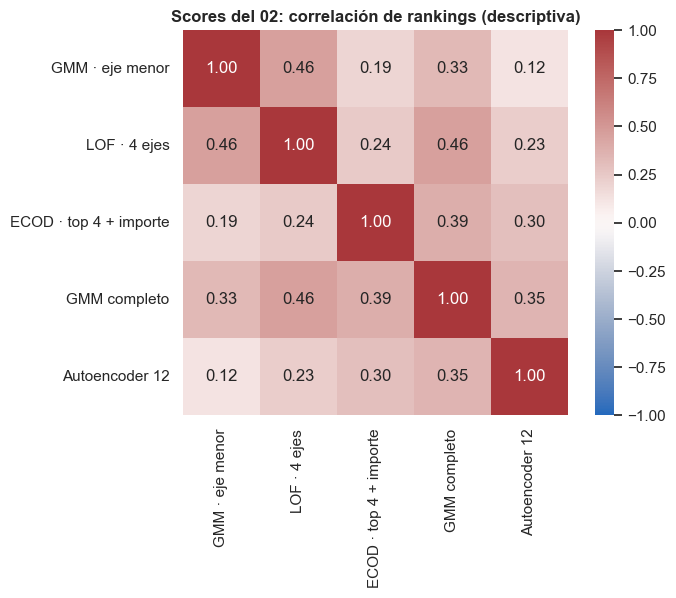

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
rho = S02_TR.corr(method="spearman")
sns.heatmap(rho, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True,
            xticklabels=DESCRIPCION.detector, yticklabels=DESCRIPCION.detector, ax=ax)
ax.set(title="Scores del 02: correlación de rankings (descriptiva)")
mostrar_figura("02_correlacion_scores")

> **Conclusión:** los cinco scores del 02 están completos y alineados con las **284.807 filas** del dataset. La máxima correlación de Spearman entre scores distintos es **0,46**. Miden perspectivas diferentes de la rareza, pero esa diversidad no garantiza que añadan información al XGBoost. → **Impacto:** se prueban exactamente una columna (GMM eje) y las cinco columnas seleccionadas, sin añadir otros modelos.

## 3. ¿Cómo evitamos que la validación se filtre?

**Qué miramos y por qué.** Ser OOF en el 02 no basta para reutilizar esas columnas en la misma CV: el score de una fila de entrenamiento del híbrido puede proceder de un detector que vio las filas del fold externo de validación. Por eso **recalculamos los scores en dos niveles**:

1. Se reserva el fold externo de validación, igual que en el 03.
2. En el entrenamiento externo, cinco folds internos por `group_id` generan scores OOF para entrenar XGBoost. Cada detector aprende solo con normales del entrenamiento interno.
3. Se reajustan los detectores con los normales del entrenamiento externo y se puntúa la validación externa.
4. El XGBoost entrenado con las variables originales + scores internos OOF puntúa esa validación externa.

Los escaladores, los ejes y el autoencoder se ajustan en su conjunto de entrenamiento. Para ECOD, las cuatro variables por AUPR se seleccionan **dentro de ese conjunto**, usando sus etiquetas, y luego ECOD se ajusta solo con sus normales. Las familias y configuraciones elegidas en el 02 y 03 quedan congeladas: se evalúa una ampliación de un proyecto ya explorado, no una estimación libre de toda selección previa.

La frecuencia de importe conserva la definición transductiva del 01 (construcción + producción, sin etiquetas), común a los tres modelos. Los duplicados nunca cruzan los folds. Una caché local identificada por datos, código y versiones evita repetir ajustes al volver a ejecutar el notebook.

Las cuatro clases siguientes reproducen las implementaciones del 02. Se incluyen aquí para que el 04 pueda ejecutarse sin ejecutar sus celdas ni importar código externo. El GMM procede de scikit-learn.

In [7]:
class EjesPropios(TransformerMixin, BaseEstimator):
    """Coordenadas en los k ejes de menor varianza de los normales estandarizados (k=1: el eje menor de §3).
    con_originales=True: las añade a las variables originales."""
    def __init__(self, k=1, con_originales=False):
        self.k, self.con_originales = k, con_originales
    def fit(self, X, y=None):
        self.sc_ = StandardScaler().fit(X)
        self.V_ = np.linalg.eigh(np.cov(self.sc_.transform(X).T))[1][:, :self.k]    # autovalores en orden creciente
        return self
    def transform(self, X):
        Z = self.sc_.transform(X) @ self.V_
        return np.c_[X, Z] if self.con_originales else Z

class LOFRef(OutlierMixin, BaseEstimator):
    """LOF de novedad ajustado con una referencia: n normales al azar (n=None: todos), deduplicados o no.
    score_samples = −LOF (mayor = más normal)."""
    def __init__(self, n_neighbors=20, n=20_000, dedup=False, random_state=SEED):
        self.n_neighbors, self.n, self.dedup, self.random_state = n_neighbors, n, dedup, random_state
    def fit(self, X, y=None):
        R = np.unique(X, axis=0) if self.dedup else X           # una fila por grupo de filas idénticas
        if self.n and self.n < len(R):
            R = R[np.random.default_rng(self.random_state).choice(len(R), self.n, replace=False)]
        self.lof_ = LocalOutlierFactor(n_neighbors=self.n_neighbors, novelty=True).fit(R)
        return self
    def score_samples(self, X):
        return self.lof_.score_samples(X)

class ECOD(OutlierMixin, BaseEstimator):
    """Empirical-CDF Outlier Detection: score_samples = −max(Σ cola izq., Σ cola der., Σ cola por asimetría) (mayor = más normal)."""
    def fit(self, X, y=None):
        self.orden_, self.asim_ = np.sort(X, axis=0), stats.skew(X, axis=0)
        return self
    def colas(self, X):
        """−log P(X_j ≤ x_j) y −log P(X_j ≥ x_j) con la ECDF de los normales (+1: ningún log 0 fuera de rango)."""
        n = len(self.orden_)
        izq = np.column_stack([np.searchsorted(o, x, side="right") for o, x in zip(self.orden_.T, X.T)])
        der = n - np.column_stack([np.searchsorted(o, x, side="left") for o, x in zip(self.orden_.T, X.T)])
        return -np.log((izq + 1) / (n + 1)), -np.log((der + 1) / (n + 1))
    def score_samples(self, X):
        izq, der = self.colas(X)
        auto = np.where(self.asim_ < 0, izq, der)                # cola izquierda si la variable es asimétrica a la izquierda
        return -np.maximum.reduce([izq.sum(1), der.sum(1), auto.sum(1)])

class Autoencoder(OutlierMixin, BaseEstimator):
    """AE denso d → 16 → code → 16 → d: score_samples = −MSE de reconstrucción por fila (mayor = más normal)."""
    def __init__(self, code=8, epochs=60, lr=1e-3, batch=256, patience=5, n_max=40_000, random_state=SEED):
        self.code, self.epochs, self.lr, self.batch = code, epochs, lr, batch
        self.patience, self.n_max, self.random_state = patience, n_max, random_state

    def fit(self, X, y=None):
        torch.manual_seed(self.random_state); torch.set_num_threads(2)       # determinista y sin saturar los núcleos
        X = np.asarray(X, np.float32)[np.random.default_rng(self.random_state).permutation(len(X))[:self.n_max]]
        nv = len(X) // 10
        Xv, Xe = torch.from_numpy(X[:nv]), torch.from_numpy(X[nv:])         # 10 % de normales para early stopping
        d = X.shape[1]
        self.net_ = nn.Sequential(nn.Linear(d, 16), nn.ReLU(), nn.Linear(16, self.code),
                                  nn.Linear(self.code, 16), nn.ReLU(), nn.Linear(16, d))
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr)
        mejor, paciencia = np.inf, 0
        for ep in range(self.epochs):
            for b in torch.randperm(len(Xe)).split(self.batch):
                loss = ((self.net_(Xe[b]) - Xe[b]) ** 2).mean()
                opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                val = ((self.net_(Xv) - Xv) ** 2).mean().item()
            if val < mejor:
                mejor, paciencia, pesos = val, 0, copy.deepcopy(self.net_.state_dict())
            elif (paciencia := paciencia + 1) >= self.patience:
                break
        self.net_.load_state_dict(pesos)
        self.epocas_ = ep + 1
        return self

    def reconstruir(self, X):
        with torch.no_grad():
            return self.net_(torch.from_numpy(np.asarray(X, np.float32))).numpy().astype(float)

    def score_samples(self, X):
        return -((np.asarray(X, float) - self.reconstruir(X)) ** 2).mean(axis=1)

In [8]:
# Firma automática del código al final de esta celda.

def top4_entrenamiento(X, y):
    a = [max(average_precision_score(y, X[:, j]), average_precision_score(y, -X[:, j])) for j in range(20)]
    return np.argsort(-np.asarray(a), kind="stable")[:4].tolist()

def ajustar_detectores(X, y, columnas=SCORES):
    # X e y pertenecen exclusivamente al entrenamiento de este nivel.
    normales = np.asarray(y) == 0
    modelos, top = {}, None
    for c in columnas:
        cols = list(range(len(FEATURES)))
        if c == "s02_gmm_eje":
            est = make_pipeline(EjesPropios(1), make_pipe(GaussianMixture(5, random_state=SEED), "robust"))
        elif c == "s02_lof_4ejes":
            est = make_pipeline(EjesPropios(4), make_pipe(LOFRef(20), "standard"))
        elif c == "s02_ecod_top4":
            top = top4_entrenamiento(X, y)
            cols, est = top + [20, 21], ECOD()
        elif c == "s02_gmm_full":
            est = make_pipe(GaussianMixture(5, covariance_type="full", random_state=SEED), "robust")
        elif c == "s02_ae12":
            est = make_pipe(Autoencoder(12), "robust")
        else:
            raise ValueError(c)
        with threadpool_limits(2):
            est.fit(X[normales][:, cols])
        modelos[c] = (est, cols)
    return modelos, top

def puntuar_detectores(modelos, X, columnas=SCORES):
    with threadpool_limits(2):
        S = np.column_stack([-modelos[c][0].score_samples(X[:, modelos[c][1]]) for c in columnas])
    assert np.isfinite(S).all()
    return S

def bloque_seguro(X, y, grupos, destinos, etiqueta, columnas=SCORES):
    # Genera el entrenamiento OOF interno y los scores nuevos con refit completo.
    # Los destinos no se utilizan para ajustar ni elegir columnas.
    X, y, grupos = np.asarray(X, float), np.asarray(y, int), np.asarray(grupos)
    firma = hashlib.sha256()
    for a in [X, y, grupos, *destinos]:
        a = np.ascontiguousarray(a)
        firma.update(str((a.shape, a.dtype)).encode())
        firma.update(a.tobytes())
    firma.update(json.dumps([firma_detectores(), VERSIONES, list(columnas), list(FEATURES), SEED], sort_keys=True).encode())
    archivo = CACHE_DIR / (firma.hexdigest() + ".npz")
    if archivo.exists():
        with np.load(archivo, allow_pickle=False) as z:
            return z["oof"], [z[f"destino{i}"] for i in range(len(destinos))], json.loads(str(z["auditoria"]))
    t0 = time.time()
    oof, cobertura, auditoria = np.full((len(y), len(columnas)), np.nan), np.zeros(len(y), int), []
    internos = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
    for k, (it, iv) in enumerate(internos.split(X, y, grupos)):
        assert not np.intersect1d(grupos[it], grupos[iv]).size
        modelos, top = ajustar_detectores(X[it], y[it], columnas)
        oof[iv] = puntuar_detectores(modelos, X[iv], columnas)
        cobertura[iv] += 1
        auditoria.append({"etapa": etiqueta, "nivel": "interno", "fold": k,
                          "filas_ajuste": len(it), "normales_ajuste": int((y[it] == 0).sum()),
                          "fraudes_para_seleccion_top4": int(y[it].sum()), "filas_puntuadas": len(iv),
                          "grupos_compartidos": 0, "top4": [FEATURES[j] for j in top] if top is not None else []})
        print(f"{etiqueta}: scores internos {k+1}/5 ({time.time()-t0:.0f} s)", flush=True)
    assert (cobertura == 1).all() and np.isfinite(oof).all()
    modelos, top = ajustar_detectores(X, y, columnas)
    resultados = [puntuar_detectores(modelos, np.asarray(d, float), columnas) for d in destinos]
    auditoria.append({"etapa": etiqueta, "nivel": "refit", "fold": -1,
                      "filas_ajuste": len(y), "normales_ajuste": int((y == 0).sum()),
                      "fraudes_para_seleccion_top4": int(y.sum()), "filas_puntuadas": sum(map(len, destinos)),
                      "grupos_compartidos": None, "top4": [FEATURES[j] for j in top] if top is not None else []})
    np.savez_compressed(archivo, oof=oof, auditoria=json.dumps(auditoria),
                        **{f"destino{i}": s for i, s in enumerate(resultados)})
    return oof, resultados, auditoria

def firma_detectores():
    # Bytecode, constantes y argumentos por defecto: cambia si se edita el ajuste,
    # y se mantiene al ejecutar el mismo código desde otra celda o archivo.
    import types
    def codigo(c):
        return [c.co_code.hex(), c.co_names, c.co_varnames,
                [codigo(v) if isinstance(v, types.CodeType) else repr(v) for v in c.co_consts]]
    funciones = [v for cls in [EjesPropios, LOFRef, ECOD, Autoencoder]
                 for v in vars(cls).values() if isinstance(v, types.FunctionType)]
    funciones += [make_pipe, top4_entrenamiento, ajustar_detectores, puntuar_detectores, bloque_seguro]
    contenido = [(f.__qualname__, codigo(f.__code__), repr(f.__defaults__), repr(f.__kwdefaults__)) for f in funciones]
    return hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()

FIRMA_CODIGO = firma_detectores()


**Construcción de las cinco particiones externas.** Se generan los cinco scores una sola vez por partición y se comparten entre los dos híbridos. Así, el experimento de una columna usa exactamente el mismo GMM que el de cinco. Se conserva el tiempo de generación de features separado del tiempo de entrenamiento de XGBoost.

In [9]:
BLOQUES, AUDITORIA = [], []
S02_OOF = np.full((len(ya), len(SCORES)), np.nan)
t0 = time.time()
for k, (it, iv) in enumerate(cv_splits):
    assert not np.intersect1d(ga[it], ga[iv]).size
    t_fold = time.time()
    S_it, (S_iv,), audit = bloque_seguro(Xa[it], ya[it], ga[it], [Xa[iv]], f"externo {k}")
    BLOQUES.append((S_it, S_iv))
    S02_OOF[iv] = S_iv
    AUDITORIA.extend(audit)
    AUDITORIA.append({"etapa": f"externo {k}", "nivel": "externo", "fold": k,
                      "filas_ajuste": len(it), "normales_ajuste": int((ya[it] == 0).sum()),
                      "fraudes_para_seleccion_top4": int(ya[it].sum()), "filas_puntuadas": len(iv),
                      "grupos_compartidos": 0, "top4": []})
    print(f"Fold externo {k}: listo en {time.time()-t_fold:.1f} s", flush=True)
TIEMPO_SCORES_CV = time.time()-t0
assert np.isfinite(S02_OOF).all()
AUDIT_CV = pd.DataFrame(AUDITORIA)
AUDIT_CV[AUDIT_CV.nivel != "refit"].groupby("nivel").agg(particiones=("fold", "size"),
    máximo_grupos_compartidos=("grupos_compartidos", "max"), filas_puntuadas=("filas_puntuadas", "sum"))

Fold externo 0: listo en 0.0 s
Fold externo 1: listo en 0.0 s
Fold externo 2: listo en 0.0 s
Fold externo 3: listo en 0.0 s
Fold externo 4: listo en 0.0 s


,particiones,máximo_grupos_compartidos,filas_puntuadas
nivel,,,
externo,5,0.0,119618
interno,25,0.0,478472


In [10]:
comparacion_scores = pd.DataFrame({
    "AUPR del export 02": [average_precision_score(ya, S02_TR[c]) for c in SCORES],
    "AUPR externo recalculado": [average_precision_score(ya, S02_OOF[:, j]) for j in range(len(SCORES))],
    "Spearman con export 02": [stats.spearmanr(S02_TR[c], S02_OOF[:, j]).statistic for j, c in enumerate(SCORES)]
}, index=SCORES)
comparacion_scores.round(4)

,AUPR del export 02,AUPR externo recalculado,Spearman con export 02
s02_gmm_eje,0.7732,0.7732,1.0
s02_lof_4ejes,0.7324,0.7324,1.0
s02_ecod_top4,0.7406,0.7406,1.0
s02_gmm_full,0.7315,0.7315,1.0
s02_ae12,0.6993,0.6997,1.0


> **Conclusión:** la CV genera **25 particiones internas y 5 externas**, con cobertura OOF completa y **cero grupos compartidos** entre entrenamiento y validación en ambos niveles. La selección interna de ECOD produce **5 ordenaciones de cuatro variables** entre los ajustes registrados. Los exports globales del 02 sirven de contraste; no se usan para entrenar la CV de los híbridos. → **Impacto:** las diferencias medidas no se basan en detectores que hayan visto la validación externa. La selección histórica de configuraciones en 02–03 sigue siendo una limitación del experimento.

## 4. ¿Ayuda el score del GMM?

**Qué miramos y por qué.** Añadimos una sola columna: la rareza según el GMM del eje menor. Se mantienen los 400 árboles, la profundidad 3, la semilla y el resto de parámetros del XGBoost original. La pregunta es si esa síntesis de las variables facilita detectar y ordenar el fraude.

In [11]:
def evaluar_hibrido(nombre):
    indices = [SCORES.index(c) for c in EXTRAS[nombre]]
    t0, s = time.time(), np.full(len(ya), np.nan)
    for (it, iv), (S_it, S_iv) in zip(cv_splits, BLOQUES):
        Xe = np.c_[Xa[it], S_it[:, indices]]
        Xv = np.c_[Xa[iv], S_iv[:, indices]]
        m = fit(XGB_FINAL, Xe, ya[it])
        s[iv] = score(m, Xv)
    registrar(nombre, s, time.time()-t0)

evaluar_hibrido(UNO)
frente_a([UNO]).round(4)

XGBoost + score del GMM: CV AUPR = 0.8638 ± 0.0585 (5.2 s)


,media,std,Δ AUPR,peor Δ fold,folds que gana (de 5)
XGBoost + score del GMM,0.8638,0.0585,-0.0007,-0.0153,4.0


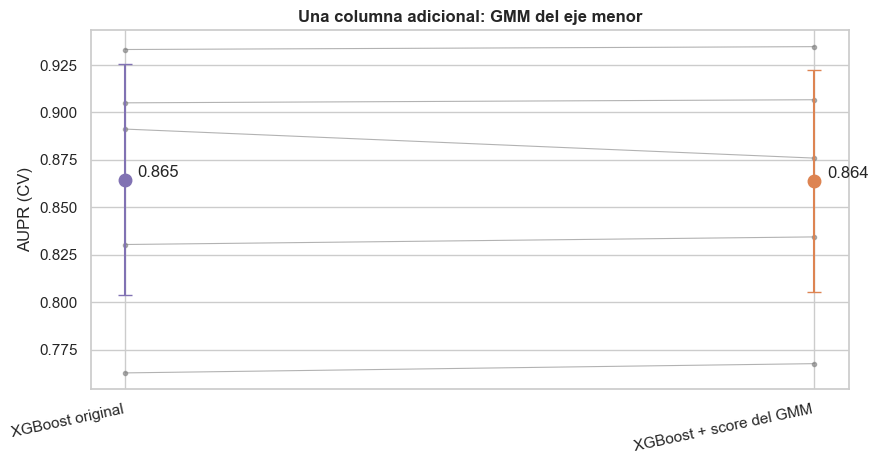

In [12]:
plot_folds([REF, UNO], "Una columna adicional: GMM del eje menor")
mostrar_figura("04_un_score")

> **Conclusión:** añadir solo el GMM obtiene **0,8638 ± 0,0585**, **-0,0007** frente a XGBoost original, y gana en **4 de 5 folds** (Δ de -0,0153 a +0,0049). El clasificador y sus parámetros son los mismos; se ha añadido una medida de rareza calculada sin la fila evaluada. → **Impacto:** esta ampliación pasa a la comparación final; la decisión aplica la regla de mejora y estabilidad de §8.

## 5. ¿Ayudan los cinco scores?

**Qué miramos y por qué.** Añadimos las cinco perspectivas elegidas en el 02: densidad en el eje menor, vecindad local, colas marginales, densidad completa y reconstrucción. El XGBoost decide cómo combinarlas con las variables originales. Se comprueba si la diversidad aporta algo frente al modelo original y frente a añadir solo el GMM.

In [13]:
evaluar_hibrido(CINCO)
display(frente_a([CINCO]).round(4))
frente_a([CINCO], referencia=UNO).round(4)

XGBoost + cinco scores del 02: CV AUPR = 0.8589 ± 0.0599 (5.9 s)


,media,std,Δ AUPR,peor Δ fold,folds que gana (de 5)
XGBoost + cinco scores del 02,0.8589,0.0599,-0.0056,-0.0124,1.0


,media,std,Δ AUPR,peor Δ fold,folds que gana (de 5)
XGBoost + cinco scores del 02,0.8589,0.0599,-0.005,-0.0165,1.0


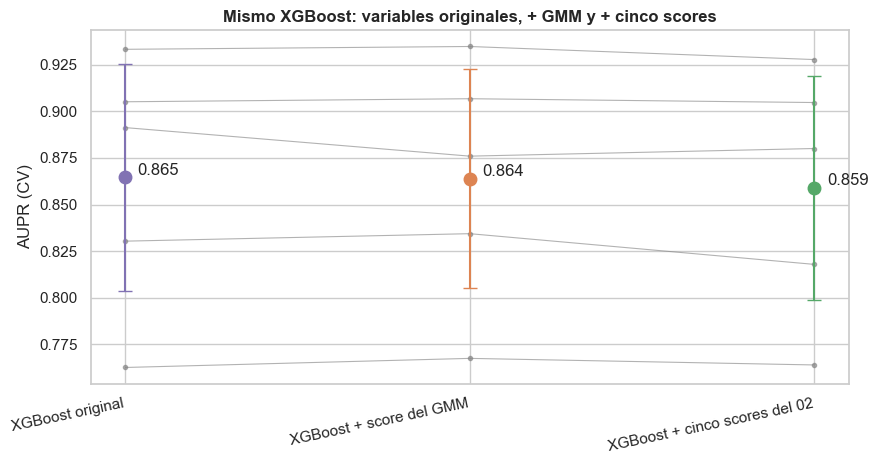

In [14]:
plot_folds(NOMBRES, "Mismo XGBoost: variables originales, + GMM y + cinco scores")
mostrar_figura("05_cinco_scores")

> **Conclusión:** añadir los cinco scores obtiene **0,8589 ± 0,0599**, **-0,0056** frente a XGBoost original, y gana en **1 de 5 folds** (Δ de -0,0124 a +0,0014). Frente a añadir solo el GMM, cambia **-0,0050** y gana en **1 de 5 folds**. → **Impacto:** más columnas y más detectores solo se justifican si aportan una mejora consistente; se comparan con la alternativa de una columna y con el original.

## 5.1. ¿Ayuda dar prioridad a las variables más predictivas?

**Qué miramos y por qué.** Añadir ejes o scores no equivale a favorecer directamente las variables originales. El XGBoost de referencia usa `colsample_bytree=0.7`: cada árbol recibe una selección de columnas. Aquí `feature_weights` cambia la probabilidad de que una variable esté disponible, sin obligar a usarla ni modificar sus valores o los pesos de clase.

**Prueba fijada antes de ejecutarla.** Dos variantes con las mismas 22 variables y el resto de parámetros congelados: peso **3** para la variable más predictiva o para las **cuatro primeras**, y peso **1** para las demás. Se añade un control con todos los pesos iguales a 1: permite distinguir la prioridad del posible cambio aleatorio al activar el muestreo ponderado. No se buscan otros pesos ni semillas.

**Selección sin usar el fold evaluado.** En cada entrenamiento externo se toma la primera partición de un `StratifiedGroupKFold(5, shuffle=True, random_state=42)` interno. Se ajusta el XGBoost original en el entrenamiento interno y se ordenan las 22 variables por la caída de AUPR al permutarlas en la validación interna (3 repeticiones). Después se reajusta cada variante con **todo el entrenamiento externo** y se puntúa su validación externa. Los duplicados permanecen agrupados en ambos niveles. Esta importancia mide utilidad predictiva en ese modelo, no causalidad; no se reutiliza la importancia de X14 calculada sobre test.

**Comparación.** AUPR en los mismos cinco folds externos, diferencias por pares frente al original y al control uniforme. Se conserva el criterio práctico del proyecto: mejora media de al menos **0,005** y victoria en **4 de 5 folds**; para atribuirla a la prioridad se exige también frente al control. Es una prueba adicional exploratoria, no una prueba de significación ni una nueva validación independiente. Sus resultados se guardan aparte de la comparación de los tres modelos originales. El test y producción no intervienen en este experimento.

Referencia del mecanismo: [documentación de XGBoost sobre `feature_weights` y muestreo de columnas](https://xgboost.readthedocs.io/en/release_3.2.0/parameter.html).


In [4]:
from sklearn.inspection import permutation_importance

PRIO_CONTROL = "Control: pesos uniformes"
PRIO_UNA = "Prioridad ×3: primera variable"
PRIO_CUATRO = "Prioridad ×3: cuatro variables"
PRIO_VARIANTES = {PRIO_CONTROL: 0, PRIO_UNA: 1, PRIO_CUATRO: 4}
PRIO_MULTIPLICADOR, PRIO_MIN_MEJORA = 3.0, 0.005
PRIO_OOF = {n: np.full(len(ya), np.nan) for n in PRIO_VARIANTES}
PRIO_TIEMPOS = {n: 0.0 for n in PRIO_VARIANTES}
PRIO_IMPORTANCIAS, PRIO_AUDITORIA = [], []
prio_t0 = time.time()

for prio_k, (prio_it, prio_iv) in enumerate(cv_splits):
    assert not np.intersect1d(ga[prio_it], ga[prio_iv]).size
    prio_interno = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    prio_ie, prio_is = next(prio_interno.split(Xa[prio_it], ya[prio_it], ga[prio_it]))
    prio_ajuste, prio_seleccion = prio_it[prio_ie], prio_it[prio_is]
    assert not np.intersect1d(ga[prio_ajuste], ga[prio_seleccion]).size
    assert not np.intersect1d(np.r_[prio_ajuste, prio_seleccion], prio_iv).size
    prio_selector = fit(XGB_FINAL, Xa[prio_ajuste], ya[prio_ajuste])
    prio_imp = permutation_importance(
        prio_selector, Xa[prio_seleccion], ya[prio_seleccion],
        scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=1)
    prio_orden = np.argsort(-prio_imp.importances_mean, kind="stable")
    prio_nombres = [FEATURES[j] for j in prio_orden]
    for prio_puesto, prio_j in enumerate(prio_orden, start=1):
        PRIO_IMPORTANCIAS.append({
            "fold": prio_k, "puesto": prio_puesto, "variable": FEATURES[prio_j],
            "caida_aupr_interna": prio_imp.importances_mean[prio_j],
            "std_interna": prio_imp.importances_std[prio_j]})
    PRIO_AUDITORIA.append({
        "fold": prio_k, "filas_ajuste_interno": len(prio_ajuste),
        "filas_seleccion_interna": len(prio_seleccion), "filas_validacion_externa": len(prio_iv),
        "grupos_compartidos_internos": 0, "grupos_compartidos_externos": 0,
        "primera_variable": prio_nombres[0], "cuatro_variables": ", ".join(prio_nombres[:4])})
    for prio_nombre, prio_top in PRIO_VARIANTES.items():
        prio_pesos = np.ones(len(FEATURES), dtype=float)
        prio_pesos[prio_orden[:prio_top]] = PRIO_MULTIPLICADOR
        prio_t = time.time()
        prio_modelo = clone(XGB_FINAL).set_params(feature_weights=prio_pesos)
        prio_modelo.fit(Xa[prio_it], ya[prio_it])
        PRIO_OOF[prio_nombre][prio_iv] = score(prio_modelo, Xa[prio_iv])
        PRIO_TIEMPOS[prio_nombre] += time.time()-prio_t
    print(f"Fold {prio_k}: primera = {prio_nombres[0]}; cuatro = {', '.join(prio_nombres[:4])}", flush=True)

PRIO_FOLDS = pd.DataFrame(
    {REF: por_fold(REF), **{
        n: [average_precision_score(ya[iv], s[iv]) for _, iv in cv_splits]
        for n, s in PRIO_OOF.items()}}, index=pd.Index(range(5), name="fold"))
PRIO_RESUMEN = pd.DataFrame({
    "AUPR media": PRIO_FOLDS.mean(), "std": PRIO_FOLDS.std(ddof=0),
    "Δ vs original": PRIO_FOLDS.sub(PRIO_FOLDS[REF], axis=0).mean(),
    "victorias vs original": PRIO_FOLDS.gt(PRIO_FOLDS[REF], axis=0).sum(),
    "Δ vs uniforme": PRIO_FOLDS.sub(PRIO_FOLDS[PRIO_CONTROL], axis=0).mean(),
    "victorias vs uniforme": PRIO_FOLDS.gt(PRIO_FOLDS[PRIO_CONTROL], axis=0).sum()})
PRIO_RESUMEN.index.name = "modelo"
PRIO_RESUMEN["cumple criterio frente a ambos"] = (
    PRIO_RESUMEN["Δ vs original"].ge(PRIO_MIN_MEJORA)
    & PRIO_RESUMEN["victorias vs original"].ge(4)
    & PRIO_RESUMEN["Δ vs uniforme"].ge(PRIO_MIN_MEJORA)
    & PRIO_RESUMEN["victorias vs uniforme"].ge(4))
PRIO_AUDITORIA = pd.DataFrame(PRIO_AUDITORIA).set_index("fold")
PRIO_IMPORTANCIAS = pd.DataFrame(PRIO_IMPORTANCIAS)
assert all(np.isfinite(s).all() for s in PRIO_OOF.values())
assert PRIO_FOLDS.shape == (5, 4)
assert (PRIO_AUDITORIA[["grupos_compartidos_internos", "grupos_compartidos_externos"]] == 0).all().all()
PRIO_SCORES = claves.copy()
PRIO_SCORES["s04_xgb_original"] = OOF[REF]
PRIO_COLUMNAS = {PRIO_CONTROL: "s04_pesos_uniformes", PRIO_UNA: "s04_prioridad_una", PRIO_CUATRO: "s04_prioridad_cuatro"}
for prio_nombre, prio_columna in PRIO_COLUMNAS.items():
    PRIO_SCORES[prio_columna] = PRIO_OOF[prio_nombre]
PRIO_RESUMEN.to_csv(OUTPUT_DIR / "04_prioridad_metricas_cv.csv")
PRIO_FOLDS.to_csv(OUTPUT_DIR / "04_prioridad_aupr_por_fold.csv")
PRIO_AUDITORIA.to_csv(OUTPUT_DIR / "04_prioridad_auditoria.csv")
PRIO_IMPORTANCIAS.to_csv(OUTPUT_DIR / "04_prioridad_importancias_internas.csv", index=False)
PRIO_SCORES.to_csv(OUTPUT_DIR / "04_prioridad_scores_oof.csv", index=False, float_format="%.10g")
# Reproducir la métrica desde el CSV comprueba orden, cobertura y precisión de exportación.
prio_releido = pd.read_csv(OUTPUT_DIR / "04_prioridad_scores_oof.csv")
assert prio_releido[["split", "row_id"]].equals(claves)
for prio_nombre, prio_columna in PRIO_COLUMNAS.items():
    assert np.allclose(
        [average_precision_score(ya[iv], prio_releido[prio_columna].to_numpy()[iv]) for _, iv in cv_splits],
        PRIO_FOLDS[prio_nombre], atol=1e-8, rtol=0)
print(f"Experimento completo: {time.time()-prio_t0:.1f} s; solo predicciones OOF de train.")
display(PRIO_RESUMEN.round(4))
display(PRIO_AUDITORIA[["primera_variable", "cuatro_variables"]])


Fold 0: primera = X14; cuatro = X14, X4, X10, X3


Fold 1: primera = X10; cuatro = X10, X14, X4, amount_freq


Fold 2: primera = X14; cuatro = X14, amount_freq, X12, X4


Fold 3: primera = X14; cuatro = X14, X10, X4, X8


Fold 4: primera = X14; cuatro = X14, amount_freq, X8, X10


Experimento completo: 114.3 s; solo predicciones OOF de train.


,AUPR media,std,Δ vs original,victorias vs original,Δ vs uniforme,victorias vs uniforme,cumple criterio frente a ambos
modelo,,,,,,,
XGBoost original,0.8645,0.0610,0.0000,0,0.0043,4,False
Control: pesos uniformes,0.8602,0.0592,-0.0043,1,0.0000,0,False
Prioridad ×3: primera variable,0.8636,0.0582,-0.0009,2,0.0034,3,False
Prioridad ×3: cuatro variables,0.8645,0.0605,-0.0000,1,0.0043,4,False


,primera_variable,cuatro_variables
fold,,
0,X14,"X14, X4, X10, X3"
1,X10,"X10, X14, X4, amount_freq"
2,X14,"X14, amount_freq, X12, X4"
3,X14,"X14, X10, X4, X8"
4,X14,"X14, amount_freq, X8, X10"


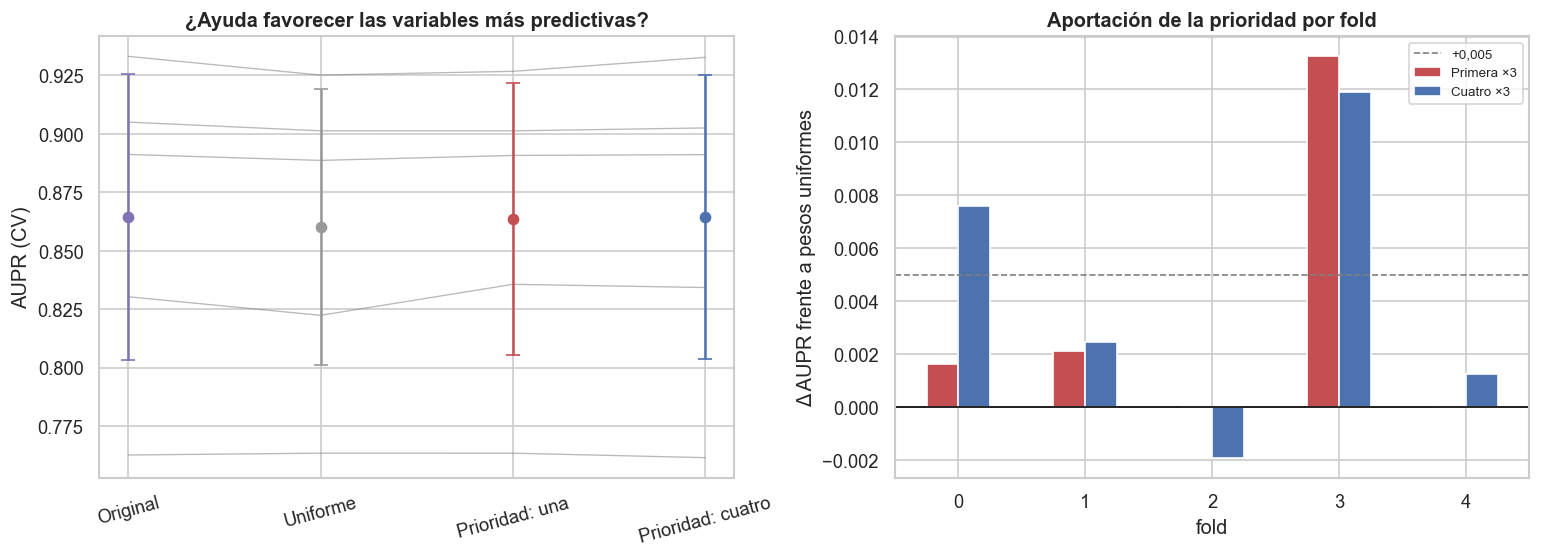

In [5]:
prio_fig, (prio_ax1, prio_ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
prio_etiquetas = ["Original", "Uniforme", "Prioridad: una", "Prioridad: cuatro"]
prio_colores = [COLORES[REF], "#999999", "#c44e52", "#4c72b0"]
for prio_k in PRIO_FOLDS.index:
    prio_ax1.plot(range(4), PRIO_FOLDS.loc[prio_k], color="grey", alpha=.55, lw=.8)
for prio_j, prio_nombre in enumerate(PRIO_FOLDS.columns):
    prio_ax1.errorbar(prio_j, PRIO_RESUMEN.loc[prio_nombre, "AUPR media"],
                     yerr=PRIO_RESUMEN.loc[prio_nombre, "std"], fmt="o", capsize=4,
                     color=prio_colores[prio_j])
prio_ax1.set(xticks=range(4), xticklabels=prio_etiquetas, ylabel="AUPR (CV)",
             title="¿Ayuda favorecer las variables más predictivas?")
prio_ax1.tick_params(axis="x", labelrotation=15)
prio_deltas = PRIO_FOLDS[[PRIO_UNA, PRIO_CUATRO]].sub(PRIO_FOLDS[PRIO_CONTROL], axis=0)
prio_deltas.columns = ["Primera ×3", "Cuatro ×3"]
prio_deltas.plot.bar(ax=prio_ax2, color=prio_colores[2:], rot=0)
prio_ax2.axhline(0, color="black", lw=1)
prio_ax2.axhline(PRIO_MIN_MEJORA, color="grey", ls="--", lw=1, label="+0,005")
prio_ax2.set(ylabel="Δ AUPR frente a pesos uniformes", title="Aportación de la prioridad por fold")
prio_ax2.legend(fontsize=8)
prio_fig.tight_layout()
prio_ruta_figura = FIG_DIR / "05bis_prioridad_variables.png"
prio_fig.savefig(prio_ruta_figura, dpi=120, bbox_inches="tight")
plt.close(prio_fig)
from IPython.display import Image
display(Image(filename=str(prio_ruta_figura)))


In [6]:
from IPython.display import Markdown

prio_lineas = []
for prio_nombre in [PRIO_UNA, PRIO_CUATRO]:
    prio_r = PRIO_RESUMEN.loc[prio_nombre]
    prio_lineas.append(
        f"**{prio_nombre}**: AUPR **{prio_r['AUPR media']:.4f} ± {prio_r['std']:.4f}**; "
        f"Δ frente al original **{prio_r['Δ vs original']:+.5f}** "
        f"({int(prio_r['victorias vs original'])}/5 victorias) y frente al control uniforme "
        f"**{prio_r['Δ vs uniforme']:+.4f}** ({int(prio_r['victorias vs uniforme'])}/5).")
prio_candidatos = [n for n in [PRIO_UNA, PRIO_CUATRO]
                   if PRIO_RESUMEN.loc[n, "cumple criterio frente a ambos"]]
if prio_candidatos:
    prio_impacto = ("Cumplen el criterio práctico: **" + ", ".join(prio_candidatos)
        + "**. La prioridad queda como candidata para revisar la selección final del proyecto; "
          "este experimento no la valida en test ni genera un nuevo entregable de producción.")
else:
    prio_impacto = ("**Ninguna variante cumple el criterio de mejora frente al original y al control uniforme.** "
        "No se incorpora la prioridad al modelo final: las variables más predictivas ya estaban disponibles "
        "y aumentar su probabilidad de selección no aporta una mejora consistente en esta prueba.")
display(Markdown(
    "> **Conclusión:** el original obtiene **"
    + f"{PRIO_RESUMEN.loc[REF, 'AUPR media']:.4f}"
    + "** y el control uniforme **"
    + f"{PRIO_RESUMEN.loc[PRIO_CONTROL, 'AUPR media']:.4f}**. "
    + " ".join(prio_lineas) + " → **Impacto:** " + prio_impacto
    + " La elección de variables se ha realizado dentro de cada entrenamiento externo; "
      "cinco folds y una sola partición interna por fold limitan la precisión de la conclusión."))


> **Conclusión:** el original obtiene **0.8645** y el control uniforme **0.8602**. **Prioridad ×3: primera variable**: AUPR **0.8636 ± 0.0582**; Δ frente al original **-0.00090** (2/5 victorias) y frente al control uniforme **+0.0034** (3/5). **Prioridad ×3: cuatro variables**: AUPR **0.8645 ± 0.0605**; Δ frente al original **-0.00004** (1/5 victorias) y frente al control uniforme **+0.0043** (4/5). → **Impacto:** **Ninguna variante cumple el criterio de mejora frente al original y al control uniforme.** No se incorpora la prioridad al modelo final: las variables más predictivas ya estaban disponibles y aumentar su probabilidad de selección no aporta una mejora consistente en esta prueba. La elección de variables se ha realizado dentro de cada entrenamiento externo; cinco folds y una sola partición interna por fold limitan la precisión de la conclusión.

---
# PARTE II · COMPARACIÓN Y ENTREGA

Se comparan los tres modelos, su recuperación de fraudes y su coste. La elección se cierra antes de puntuar el test. Después se confirma, se explica y se reajusta con toda construcción para generar el entregable.

## 6. ¿Qué modelo gana en CV?

**Qué miramos y por qué.** No basta con una media más alta: se comparan las diferencias en los mismos cinco folds. La variabilidad entre particiones mide la dificultad de los datos; no es un intervalo de confianza. Se separa el coste de generar los scores del coste de entrenar el clasificador. El tiempo compartido de generación comprende los cinco detectores y no se atribuye artificialmente al híbrido de una sola columna.

In [15]:
CV = tabla_cv()
display(CV.round(4))
COMPARACION = frente_a([UNO, CINCO])
display(COMPARACION.round(4))
print(f"Generación compartida de cinco scores, incluida lectura de caché si existe: {TIEMPO_SCORES_CV:.1f} s")
FOLDS = pd.DataFrame({n: por_fold(n) for n in NOMBRES}, index=[f"fold {k}" for k in range(5)])
DELTA = FOLDS[[UNO, CINCO]].sub(FOLDS[REF], axis=0)
DELTA.round(4)

,familia,n_feats,media,std,segundos,fold0,fold1,fold2,fold3,fold4
modelo,,,,,,,,,,
XGBoost original,boosting,22,0.864502,0.061003,5.144544,0.933171,0.891226,0.762681,0.830371,0.905059
XGBoost + score del GMM,híbrido,23,0.863848,0.058548,5.24841,0.934683,0.875924,0.767559,0.83438,0.906695
XGBoost + cinco scores del 02,híbrido,27,0.858861,0.059913,5.876892,0.927677,0.880017,0.764034,0.817923,0.904653


,media,std,Δ AUPR,peor Δ fold,folds que gana (de 5)
XGBoost + score del GMM,0.8638,0.0585,-0.0007,-0.0153,4.0
XGBoost + cinco scores del 02,0.8589,0.0599,-0.0056,-0.0124,1.0


Generación compartida de cinco scores, incluida lectura de caché si existe: 0.3 s


,XGBoost + score del GMM,XGBoost + cinco scores del 02
fold 0,0.0015,-0.0055
fold 1,-0.0153,-0.0112
fold 2,0.0049,0.0014
fold 3,0.0040,-0.0124
fold 4,0.0016,-0.0004


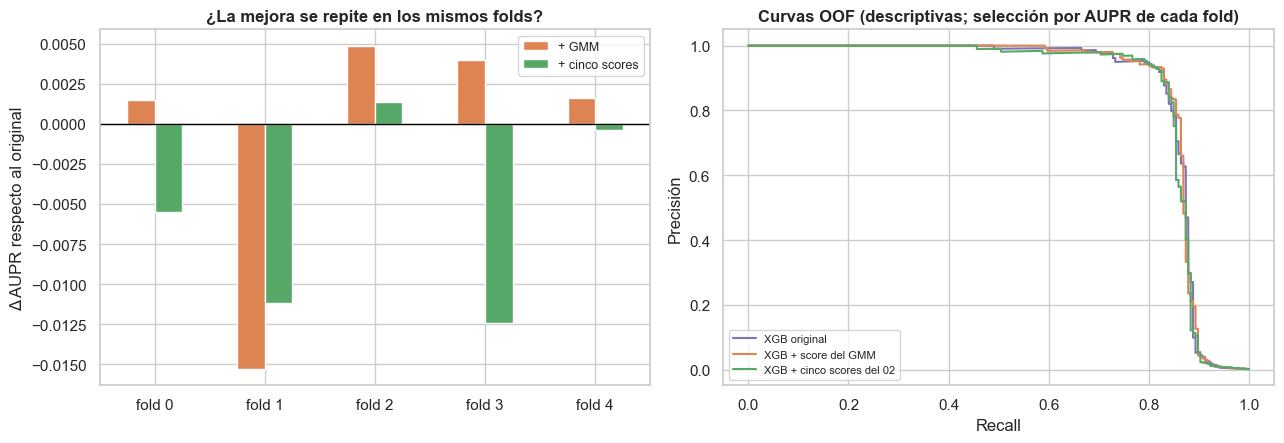

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
DELTA.plot.bar(ax=a1, color=[COLORES[UNO], COLORES[CINCO]], rot=0)
a1.axhline(0, c="black", lw=1)
a1.set(ylabel="Δ AUPR respecto al original", title="¿La mejora se repite en los mismos folds?")
handles, _ = a1.get_legend_handles_labels()
a1.legend(handles=handles, labels=["+ GMM", "+ cinco scores"], fontsize=9)
for n in NOMBRES:
    p, r, _ = precision_recall_curve(ya, OOF[n])
    a2.plot(r, p, color=COLORES[n], label=n.replace("XGBoost", "XGB"))
a2.set(xlabel="Recall", ylabel="Precisión", title="Curvas OOF (descriptivas; selección por AUPR de cada fold)")
a2.legend(fontsize=8)
fig.tight_layout()
mostrar_figura("06_comparacion_cv")

> **Conclusión:** la mayor AUPR media corresponde a **XGBoost original**, con **0,8645 ± 0,0610**. El híbrido de una columna da **0,8638** y el de cinco **0,8589**. Las diferencias se valoran fold a fold; las curvas OOF agrupadas son descriptivas y no sustituyen a esa comparación. → **Impacto:** ninguno mejora consistentemente al original; se aplica la regla conservadora de §8.

## 7. ¿Recupera otros fraudes?

**Qué miramos y por qué.** Con el mismo corte descriptivo del 02–03, un score por encima del p99 de las normales del fold equivale aproximadamente a un 1 % de falsas alarmas. Se cuentan los fraudes recuperados y perdidos respecto al original, y la precisión al revisar las 20, 50 y 100 operaciones más sospechosas de cada fold. Este umbral usa las etiquetas de validación **solo para comparar a igual tasa de falsas alarmas**, no para definir un umbral de producción.

In [17]:
def captura_oof(s):
    cap = np.zeros(len(ya), bool)
    for _, iv in cv_splits:
        umbral = np.quantile(s[iv][ya[iv] == 0], .99)
        cap[iv] = s[iv] > umbral
    return cap

CAP = {n: captura_oof(OOF[n]) for n in NOMBRES}
f = ya == 1
CAPTURA = pd.DataFrame({n: {"fraudes detectados": int((CAP[n] & f).sum()),
                            "recall": (CAP[n] & f).sum()/f.sum(),
                            "recupera del original": int((CAP[n] & ~CAP[REF] & f).sum()),
                            "pierde del original": int((~CAP[n] & CAP[REF] & f).sum()),
                            "falsas alarmas (%)": 100*CAP[n][~f].mean()}
                       for n in NOMBRES}).T
TOP = pd.DataFrame({n: {f"top {k}": np.mean([ya[iv][np.argsort(-OOF[n][iv])[:k]].mean() for _, iv in cv_splits])
                        for k in [20, 50, 100]} for n in NOMBRES}).T
display(CAPTURA.round(4))
TOP.round(4)

,fraudes detectados,recall,recupera del original,pierde del original,falsas alarmas (%)
XGBoost original,183.0,0.8883,0.0,0.0,1.0007
XGBoost + score del GMM,184.0,0.8932,2.0,1.0,1.0007
XGBoost + cinco scores del 02,183.0,0.8883,2.0,2.0,0.9982


,top 20,top 50,top 100
XGBoost original,1.0,0.712,0.362
XGBoost + score del GMM,1.0,0.712,0.360
XGBoost + cinco scores del 02,1.0,0.704,0.362


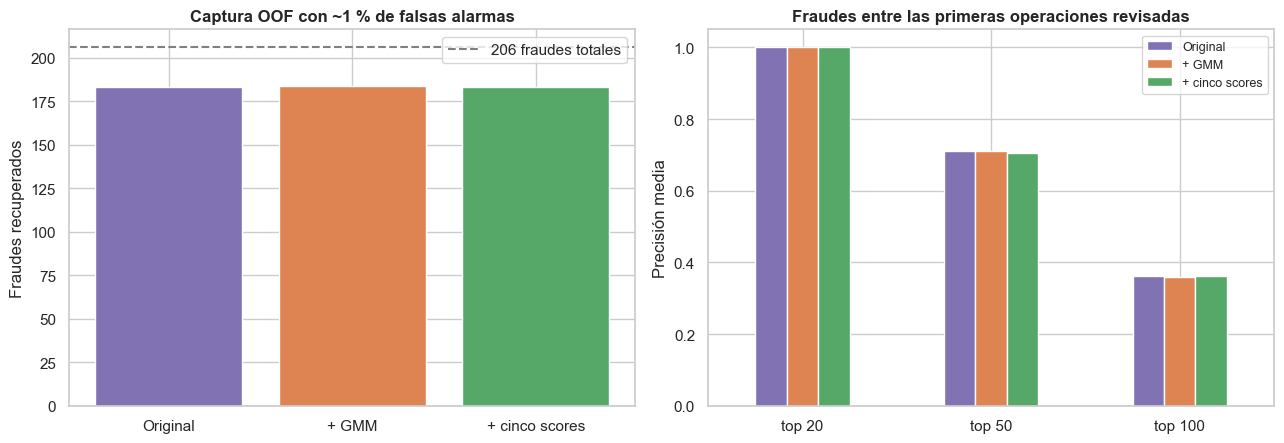

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
a1.bar(["Original", "+ GMM", "+ cinco scores"], CAPTURA["fraudes detectados"], color=list(COLORES.values()))
a1.axhline(ya.sum(), c="grey", ls="--", label=f"{ya.sum()} fraudes totales")
a1.set(ylabel="Fraudes recuperados", title="Captura OOF con ~1 % de falsas alarmas")
a1.legend()
TOP.T.plot.bar(ax=a2, color=list(COLORES.values()), rot=0)
a2.set(ylabel="Precisión media", ylim=(0, 1.05), title="Fraudes entre las primeras operaciones revisadas")
a2.legend(["Original", "+ GMM", "+ cinco scores"], fontsize=9)
fig.tight_layout()
mostrar_figura("07_recuperacion")

> **Conclusión:** con aproximadamente un 1 % de falsas alarmas, el original detecta **183 de 206**, el híbrido con GMM **184 de 206** y el de cinco scores **183 de 206**. El de una columna recupera **2** fraudes que se le escapan al original y pierde **1**; el de cinco recupera **2** y pierde **2**. → **Impacto:** esta tabla distingue recuperación adicional de una mejora del orden del ranking; no se usa para fijar un umbral de producción.

## 8. ¿Qué modelo elegimos antes del test?

**Qué miramos y por qué.** Se fija una regla conservadora: un híbrido debe mejorar la AUPR media del original **al menos 0,005** y ganar en **al menos 4 de los 5 folds**. Es un criterio práctico de mejora y estabilidad, **no una prueba de significación estadística**. Si ninguno lo cumple, se conserva el original. Si ambos lo cumplen, se prefiere una sola columna salvo que las cinco mejoren a la de una columna con esos mismos criterios. No se buscarán semillas ni hiperparámetros para cambiar la decisión.

La regla se ha definido antes de ejecutar las comparaciones; se aplica aquí, antes del test. La selección previa de modelos en 02–03 y estas tres comparaciones siguen introduciendo optimismo: el test se interpreta como confirmación interna de un proyecto ya explorado.

In [19]:
MIN_MEJORA = .005
def mejora_consistente(n, ref):
    d = por_fold(n)-por_fold(ref)
    return bool(d.mean() >= MIN_MEJORA and (d > 0).sum() >= 4)

ELEGIBLES = [n for n in [UNO, CINCO] if mejora_consistente(n, REF)]
ELEGIDO = REF
if UNO in ELEGIBLES:
    ELEGIDO = UNO
if CINCO in ELEGIBLES and (ELEGIDO == REF or mejora_consistente(CINCO, UNO)):
    ELEGIDO = CINCO
ELECCION_CV = {"modelo": ELEGIDO, "criterio": "delta_media >= 0.005 y victorias >= 4/5; preferir menos columnas",
               "elegibles": ELEGIBLES, "variables_originales": FEATURES, "scores_adicionales": EXTRAS[ELEGIDO],
               "cv_media": float(RES[ELEGIDO]["media"]), "cv_std": float(RES[ELEGIDO]["std"]),
               "semilla": SEED, "versiones": VERSIONES}
# Se congela antes de calcular cualquier score de test.
(OUTPUT_DIR / "04_seleccion_modelo.json").write_text(json.dumps(ELECCION_CV, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Modelo elegido antes del test: {ELEGIDO}")
pd.DataFrame({n: {"cumple frente al original": mejora_consistente(n, REF),
                  "Δ medio": (por_fold(n)-por_fold(REF)).mean(),
                  "victorias": int((por_fold(n)>por_fold(REF)).sum())} for n in [UNO, CINCO]}).T

Modelo elegido antes del test: XGBoost original


,cumple frente al original,Δ medio,victorias
XGBoost + score del GMM,False,-0.000653,4
XGBoost + cinco scores del 02,False,-0.005641,1


> **Conclusión:** Ningún híbrido cumple simultáneamente la mejora mínima de 0,005 y las cuatro victorias. La elección queda cerrada en **XGBoost original**, con **0,8645 ± 0,0610** en CV. La prueba de prioridad de §5.1 tampoco justifica una sustitución. → **Impacto:** se conserva esta decisión durante la confirmación en test y el reajuste final; no se cambia buscando la mejor cifra de test.

## 9. ¿Se confirma en test?

**Qué miramos y por qué.** La elección ya está cerrada. Se generan scores OOF sobre todo train para entrenar los híbridos, y los detectores reajustados con los normales de train puntúan test y producción. Los tres XGBoost se ajustan con todo train. Se informa la AUPR de test con y sin las filas que tienen copia exacta en train; el test **no cambia el modelo elegido**.

El test ya fue examinado en 02–03: esta es una confirmación interna, no un nuevo conjunto externo intacto. El bootstrap pareado usa las mismas filas en cada réplica para cuantificar la incertidumbre de la diferencia frente al original.

In [20]:
S_TR, (S_TE, S_PR), audit = bloque_seguro(Xa, ya, ga, [X_test.to_numpy(float), X_prod.to_numpy(float)], "todo train")
AUDITORIA.extend(audit)

def ampliar(X, S, nombre):
    indices = [SCORES.index(c) for c in EXTRAS[nombre]]
    return np.c_[np.asarray(X, float), S[:, indices]] if indices else np.asarray(X, float)

AJUSTADOS, SC_TEST, SC_PROD = {}, {}, {}
for n in NOMBRES:
    m = fit(XGB_FINAL, ampliar(Xa, S_TR, n), ya)
    AJUSTADOS[n] = m
    SC_TEST[n] = score(m, ampliar(X_test, S_TE, n))
    SC_PROD[n] = score(m, ampliar(X_prod, S_PR, n))
with contextlib.redirect_stdout(io.StringIO()):
    TEST = pd.DataFrame([report(n, SC_TEST[n]) for n in NOMBRES]).set_index("modelo")
TEST.insert(0, "cv_media", [RES[n]["media"] for n in TEST.index])
TEST.insert(1, "cv_std", [RES[n]["std"] for n in TEST.index])
TEST["test − CV"] = TEST["aupr"]-TEST["cv_media"]
display(TEST.round(4))
print(f"Elección mantenida: {ELEGIDO}")

,cv_media,cv_std,aupr,roc_auc,aupr_sin_dup,test − CV
modelo,,,,,,
XGBoost original,0.8645,0.0610,0.8147,0.9758,0.8015,-0.0498
XGBoost + score del GMM,0.8638,0.0585,0.8182,0.9687,0.8052,-0.0456
XGBoost + cinco scores del 02,0.8589,0.0599,0.8066,0.9704,0.7926,-0.0523


Elección mantenida: XGBoost original


In [21]:
rng = np.random.default_rng(SEED)
y_te = y_test.to_numpy()
i0, i1 = np.flatnonzero(y_te == 0), np.flatnonzero(y_te == 1)
boot = np.empty((1000, len(NOMBRES)))
for b in range(len(boot)):
    ib = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
    boot[b] = [average_precision_score(y_te[ib], SC_TEST[n][ib]) for n in NOMBRES]
BOOT = pd.DataFrame(boot, columns=NOMBRES)
IC = pd.DataFrame({n: {"AUPR test": TEST.loc[n, "aupr"], "IC 2.5 %": BOOT[n].quantile(.025),
                       "IC 97.5 %": BOOT[n].quantile(.975), "Δ frente al original": TEST.loc[n, "aupr"]-TEST.loc[REF, "aupr"],
                       "IC Δ 2.5 %": (BOOT[n]-BOOT[REF]).quantile(.025),
                       "IC Δ 97.5 %": (BOOT[n]-BOOT[REF]).quantile(.975)} for n in NOMBRES}).T
IC.round(4)

,AUPR test,IC 2.5 %,IC 97.5 %,Δ frente al original,IC Δ 2.5 %,IC Δ 97.5 %
XGBoost original,0.8147,0.7302,0.8895,0.0000,0.0000,0.0000
XGBoost + score del GMM,0.8182,0.7355,0.8888,0.0035,-0.0061,0.0149
XGBoost + cinco scores del 02,0.8066,0.7208,0.8853,-0.0081,-0.0258,0.0068


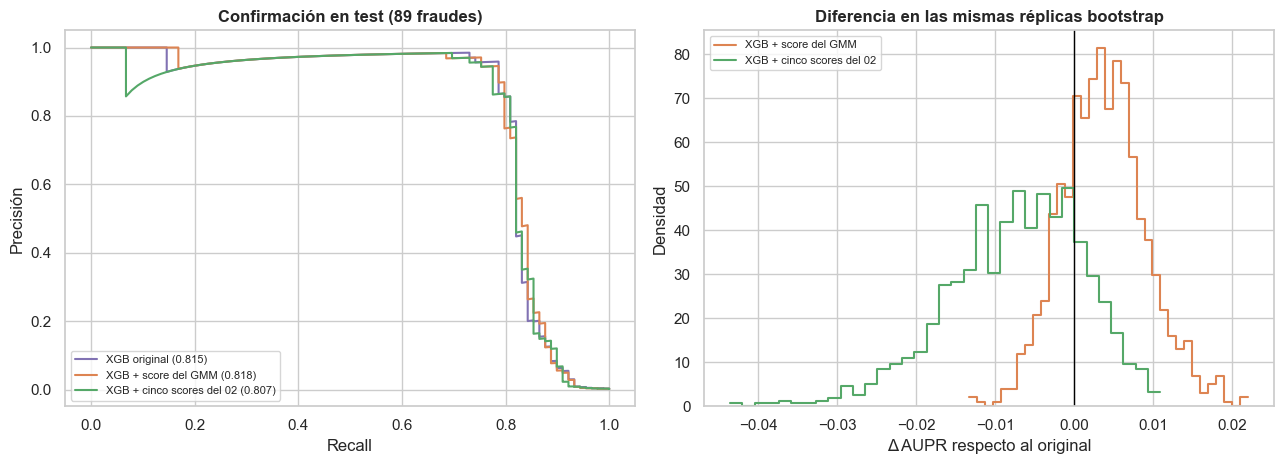

In [22]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
for n in NOMBRES:
    p, r, _ = precision_recall_curve(y_test, SC_TEST[n])
    a1.plot(r, p, color=COLORES[n], label=f"{n.replace('XGBoost', 'XGB')} ({TEST.loc[n, 'aupr']:.3f})")
a1.set(xlabel="Recall", ylabel="Precisión", title=f"Confirmación en test ({y_test.sum()} fraudes)")
a1.legend(fontsize=8, loc="lower left")
for n in [UNO, CINCO]:
    sns.histplot(BOOT[n]-BOOT[REF], bins=35, stat="density", element="step", fill=False,
                 color=COLORES[n], label=n.replace("XGBoost", "XGB"), ax=a2)
a2.axvline(0, c="black", lw=1)
a2.set(xlabel="Δ AUPR respecto al original", ylabel="Densidad", title="Diferencia en las mismas réplicas bootstrap")
a2.legend(fontsize=8)
fig.tight_layout()
mostrar_figura("09_test")

> **Conclusión:** el original obtiene **0,8147** en test. **XGBoost + score del GMM** da **0,8182** (Δ **+0,0035**; IC 95 % del Δ **-0,0061 a +0,0149**). **XGBoost + cinco scores del 02** da **0,8066** (Δ **-0,0081**; IC 95 % del Δ **-0,0258 a +0,0068**). El elegido, **XGBoost original**, obtiene **0,8015 sin duplicados**. → **Impacto:** estos resultados confirman o limitan la expectativa de CV, pero no cambian la elección. Con 89 fraudes y un test ya explorado en el proyecto, las diferencias pequeñas no justifican proclamar un nuevo ganador.

## 10. ¿En qué se fija el híbrido?

**Qué miramos y por qué.** Se explica el híbrido de cinco scores aunque el elegido sea otro: permite ver si aprovecha las nuevas columnas. Comparamos la ganancia de los cortes y la caída de AUPR al permutar las cinco columnas nuevas y las variables originales con más ganancia. Se limita el análisis a estas columnas para evitar un barrido innecesario. El test se usa aquí solo para descripción, sin cambiar la selección.

La permutación individual puede infravalorar variables redundantes y romper relaciones entre columnas. Además se permuta **todo el bloque de scores con la misma permutación de filas** para medir su aportación conjunta. Estas importancias explican el comportamiento predictivo, no causas del fraude.

In [23]:
cols_h = FEATURES + SCORES
m_h = AJUSTADOS[CINCO]
gain = pd.Series(m_h.feature_importances_, index=cols_h)
seleccion_imp = list(dict.fromkeys([*gain[FEATURES].nlargest(7).index, *SCORES]))
Xh = ampliar(X_test, S_TE, CINCO)
base_ap = average_precision_score(y_te, SC_TEST[CINCO])
rng = np.random.default_rng(SEED)
permutaciones = [rng.permutation(len(y_te)) for _ in range(5)]
filas_imp = []
for c in [*seleccion_imp, "bloque de cinco scores"]:
    indices = [cols_h.index(c)] if c != "bloque de cinco scores" else list(range(len(FEATURES), len(cols_h)))
    caidas = []
    for perm in permutaciones:
        xp = Xh.copy()
        xp[:, indices] = Xh[perm][:, indices]
        caidas.append(base_ap-average_precision_score(y_te, score(m_h, xp)))
    filas_imp.append({"variable": c, "ganancia": float(gain.get(c, np.nan)),
                      "Δ AUPR al permutar": np.mean(caidas), "std": np.std(caidas)})
IMP = pd.DataFrame(filas_imp).set_index("variable").sort_values("Δ AUPR al permutar", ascending=False)
IMP.round(4)

,ganancia,Δ AUPR al permutar,std
variable,,,
X14,0.1863,0.0651,0.0067
bloque de cinco scores,NaN,0.0180,0.0138
X4,0.0230,0.0157,0.0090
X10,0.0390,0.0134,0.0032
log1p_Amount,0.0129,0.0061,0.0039
amount_freq,0.0149,0.0060,0.0121
s02_gmm_full,0.0117,0.0043,0.0041
X7,0.0182,0.0025,0.0062
s02_lof_4ejes,0.0110,0.0021,0.0019


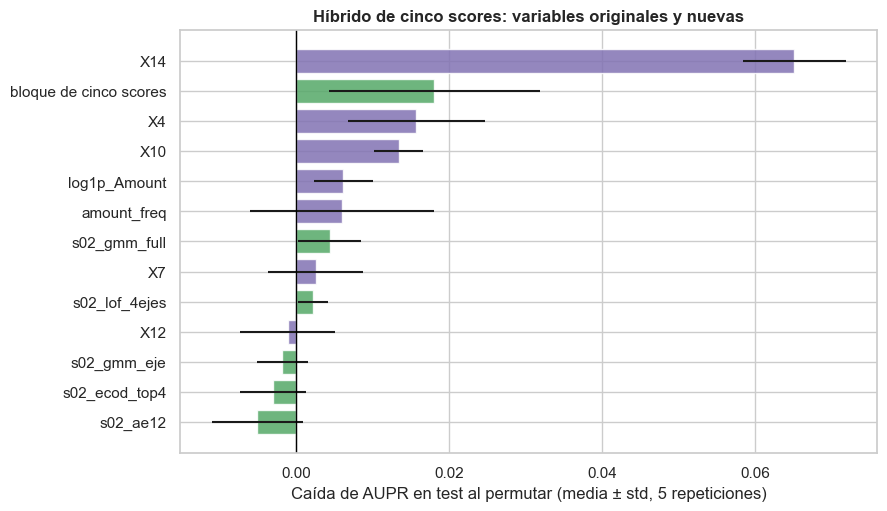

In [24]:
fig, ax = plt.subplots(figsize=(9, 5.5))
t = IMP.iloc[::-1]
col = [COLORES[CINCO] if c in SCORES or c.startswith("bloque") else COLORES[REF] for c in t.index]
ax.barh(t.index, t["Δ AUPR al permutar"], xerr=t["std"], color=col, alpha=.85)
ax.axvline(0, c="black", lw=1)
ax.set(xlabel="Caída de AUPR en test al permutar (media ± std, 5 repeticiones)",
       title="Híbrido de cinco scores: variables originales y nuevas")
mostrar_figura("10_importancia")

> **Conclusión:** entre las nuevas columnas, la mayor caída media al permutar corresponde a **s02_gmm_full** (**+0,0043** de AUPR); permutar conjuntamente los cinco scores produce **+0,0180** de caída media. La ganancia indica qué cortes utiliza el modelo, y la permutación mide su dependencia de esas columnas en este test. → **Impacto:** se documenta si el híbrido usa los scores, sin confundir su importancia dentro del modelo con una mejora frente al XGBoost original ni con una explicación causal.

## 11. Reentrenar y exportar producción

**Qué miramos y por qué.** Se guardan métricas, scores y auditoría para poder reconstruir las comparaciones. En `04_scores.csv`, train contiene predicciones externas OOF de los tres clasificadores; test y producción, predicciones de los modelos ajustados con todo train. Se une siempre por `split` + `row_id`.

**Entregable final.** Se reajusta **el modelo elegido en §8** con toda construcción, incluido el antiguo test. Si es híbrido, sus scores de entrenamiento se recalculan OOF por grupos sobre toda construcción; sus detectores se reajustan con todas las normales de construcción para puntuar producción. Si gana el original, se reajusta directamente. El archivo final tiene una columna `score`, 113.923 filas y el orden original de producción.

In [25]:
CORTO = {REF: "s04_xgb_original", UNO: "s04_xgb_gmm", CINCO: "s04_xgb_cinco"}
partes = [tr[["row_id"]].assign(split="train", **{CORTO[n]: OOF[n] for n in NOMBRES}),
          te[["row_id"]].assign(split="test", **{CORTO[n]: SC_TEST[n] for n in NOMBRES}),
          df_prod[["row_id"]].assign(split="prod", **{CORTO[n]: SC_PROD[n] for n in NOMBRES})]
scores04 = pd.concat(partes, ignore_index=True)
scores04 = df[["split", "row_id"]].merge(scores04, on=["split", "row_id"], how="left", validate="one_to_one", sort=False)
assert len(scores04) == len(df) and np.isfinite(scores04[list(CORTO.values())].to_numpy()).all()
scores04.to_csv(OUTPUT_DIR / "04_scores.csv", index=False, float_format="%.10g")
CV.to_csv(OUTPUT_DIR / "04_metricas_cv.csv")
TEST.to_csv(OUTPUT_DIR / "04_metricas_test.csv")
FOLDS.to_csv(OUTPUT_DIR / "04_aupr_por_fold.csv", index_label="fold")
IC.to_csv(OUTPUT_DIR / "04_intervalos_test.csv", index_label="modelo")
CAPTURA.to_csv(OUTPUT_DIR / "04_captura_oof.csv", index_label="modelo")
IMP.to_csv(OUTPUT_DIR / "04_importancia.csv")

# Round-trip de scores y AUPR, en el mismo orden del dataset preparado.
leido = pd.read_csv(OUTPUT_DIR / "04_scores.csv")
assert leido[["split", "row_id"]].equals(df[["split", "row_id"]].reset_index(drop=True))
for n in NOMBRES:
    s = claves.merge(leido, on=["split", "row_id"], validate="one_to_one", sort=False)[CORTO[n]].to_numpy()
    a = np.array([average_precision_score(ya[iv], s[iv]) for _, iv in cv_splits])
    assert np.allclose(a, por_fold(n), atol=1e-8)
    ste = te[["split", "row_id"]].merge(leido, on=["split", "row_id"], validate="one_to_one", sort=False)[CORTO[n]]
    assert np.isclose(average_precision_score(y_te, ste), TEST.loc[n, "aupr"], atol=1e-8)
leido.groupby("split").size().rename("filas").to_frame().T

split,prod,test,train
filas,113923,51266,119618


In [26]:
X_cons = df_const[FEATURES].to_numpy(float)
y_cons = df_const["Class"].to_numpy(int)
g_cons = df_const["group_id"].to_numpy()
if EXTRAS[ELEGIDO]:
    cols_final = EXTRAS[ELEGIDO]
    S_cons, (S_final_prod,), audit = bloque_seguro(X_cons, y_cons, g_cons,
        [X_prod.to_numpy(float)], "toda construcción", columnas=cols_final)
    AUDITORIA.extend(audit)
    X_final, X_final_prod = np.c_[X_cons, S_cons], np.c_[X_prod.to_numpy(float), S_final_prod]
else:
    X_final, X_final_prod = X_cons, X_prod.to_numpy(float)
MODELO_FINAL = fit(XGB_FINAL, X_final, y_cons)
SCORE_FINAL = score(MODELO_FINAL, X_final_prod)
save_submission(SCORE_FINAL)
sub = pd.read_csv(OUTPUT_DIR / "scores_produccion.csv")
assert sub.shape == (113_923, 1) and list(sub.columns) == ["score"]
assert np.isfinite(sub.score).all() and sub.score.between(0, 1).all()
assert np.allclose(sub.score, SCORE_FINAL)
assert df_prod.row_id.to_numpy().tolist() == list(range(len(df_prod)))
AUDITORIA_FINAL = pd.DataFrame(AUDITORIA)
AUDITORIA_FINAL.to_csv(OUTPUT_DIR / "04_auditoria_scores.csv", index=False)
assert (AUDITORIA_FINAL.loc[AUDITORIA_FINAL.nivel != "refit", "grupos_compartidos"] == 0).all()
ELECCION_CV["test_aupr_confirmacion"] = float(TEST.loc[ELEGIDO, "aupr"])
ELECCION_CV["filas_reentrenamiento"] = len(y_cons)
ELECCION_CV["fraudes_reentrenamiento"] = int(y_cons.sum())
ELECCION_CV["xgboost_parametros"] = {k: v for k, v in XGB_FINAL.get_params().items()
    if v is not None and not (isinstance(v, float) and not np.isfinite(v))}
ELECCION_CV["firma_codigo_detectores"] = firma_detectores()
ELECCION_CV["sha256_dataset"] = hashlib.sha256(PREP_CSV.read_bytes()).hexdigest()
(OUTPUT_DIR / "04_seleccion_modelo.json").write_text(json.dumps(ELECCION_CV, ensure_ascii=False, indent=2), encoding="utf-8")
top1 = lambda s: set(np.argsort(-np.asarray(s))[:len(s)//100])
ESTABILIDAD = {"Spearman con ajuste solo train": float(stats.spearmanr(SCORE_FINAL, SC_PROD[ELEGIDO]).statistic),
               "top 1 % compartido (%)": 100*len(top1(SCORE_FINAL) & top1(SC_PROD[ELEGIDO]))/(len(SCORE_FINAL)//100)}
print(f"Entregable: {ELEGIDO}; reajuste con {len(y_cons)} transacciones, {y_cons.sum()} fraudes")
pd.Series({"filas de producción": len(sub), **ESTABILIDAD}, name="valor").round(4).to_frame()

Entregable: XGBoost original; reajuste con 170884 transacciones, 295 fraudes


,valor
filas de producción,113923.0000
Spearman con ajuste solo train,0.8472
top 1 % compartido (%),63.1255


> **Conclusión:** se exportan los scores de los tres modelos para **284.807 filas** (OOF externo en train; ajuste con todo train en test y producción), las métricas y la auditoría. El entregable final usa **XGBoost original**, reajustado con **170.884 transacciones y 295 fraudes**, y contiene **113.923 filas y una sola columna `score`**, en el orden original de producción. El ranking final tiene Spearman **0,847** con el ajuste solo con train y comparte el **63,1 %** de su top 1 %. → **Impacto:** `scores_produccion.csv` queda listo como entregable y la configuración queda registrada para el 99.

## 12. Conclusiones

1. **La comparación principal mantiene las tres entradas sobre el mismo XGBoost.** Original: **0,8645 ± 0,0610**; + GMM: **0,8638 ± 0,0585**; + cinco scores: **0,8589 ± 0,0599** de AUPR en CV.
2. **Los scores se generan dentro de cada entrenamiento.** Cinco folds externos del 01, cinco internos por grupo y selección de las cuatro variables de ECOD dentro de cada conjunto de ajuste. No se entrena la CV híbrida con los OOF globales del 02.
3. **La decisión previa al test es XGBoost original.** Ningún híbrido cumple simultáneamente la mejora mínima de 0,005 y las cuatro victorias. La regla requiere Δ medio ≥ 0,005 y ≥ 4 victorias en 5 folds, y prefiere menos columnas si las cinco no mejoran consistentemente a una.
4. **La confirmación en test da 0,8147, 0,8182 y 0,8066**, respectivamente. El elegido obtiene **0,8147** y **0,8015** sin las filas con copia en train. El test no cambia la elección.
5. **La captura se mide a igual tasa de falsas alarmas.** Con ~1 % de falsas alarmas se detectan **183 de 206**, **184 de 206** y **183 de 206**, respectivamente. Una AUPR mejor puede venir de ordenar mejor los fraudes que ya se encontraban, sin recuperar muchos más.
6. **Se explica la aportación de las nuevas columnas.** Se incluyen ganancia, permutación individual y permutación conjunta del bloque. Que el modelo use un score no demuestra que mejore al original.
7. **Dar prioridad a las variables no mejora al original (§5.1).** El original obtiene **0,86450**; favorecer la primera variable, **0,86360**; favorecer las cuatro primeras, **0,86446**. Las variables se seleccionan por permutación en una validación interna de cada entrenamiento externo. Ninguna variante cumple el criterio de mejora frente al original y al control uniforme (**0,86021**); se conserva el XGBoost original. Es una prueba adicional exploratoria, sin consultar test ni producción.
8. **El entregable está generado:** `data/output/scores_produccion.csv`, **113.923 × 1**, después de reajustar el modelo elegido con toda construcción. Se conservan métricas, predicciones OOF, auditoría y configuración para el 99.

**Limitaciones.** Hay solo 206 fraudes en train y 89 en test; la CV varía entre folds. Las configuraciones del 02–03 se eligieron previamente sobre estos datos, y el test ya fue examinado en esos notebooks. Las cinco particiones externas de este experimento protegen el ajuste de los scores y del clasificador, pero no eliminan el optimismo de la selección histórica. `amount_freq` mantiene el cálculo transductivo común del 01. Los scores internos proceden de detectores entrenados con menos filas que los reajustados para predecir; el procedimiento se repite de la misma forma en CV, test y producción. El bootstrap cuantifica incertidumbre de las filas de test con modelos fijos, no de todo el proceso de selección y reentrenamiento.

**Decisión para el 99.** Usar **XGBoost original** con la configuración congelada del 03 y el procedimiento de §11. El criterio es mejora reproducida y simplicidad; la complejidad de un híbrido solo se conserva cuando la evidencia de CV la justifica.

## Conectores

**Recibe:** `01_dataset_preparado.csv`, `02_scores.csv` y `03_scores.csv`. Los exports del 02–03 se utilizan para comprobar alineación y reproducir referencias; las nuevas features se recalculan dentro de cada entrenamiento.

**Entrega:**

- `04_metricas_cv.csv`, `04_aupr_por_fold.csv`, `04_metricas_test.csv` y `04_intervalos_test.csv`: las tres comparaciones y su incertidumbre.
- `04_captura_oof.csv` y `04_importancia.csv`: recuperación de fraudes e interpretación.
- `04_scores.csv`: scores de los tres clasificadores por `split` + `row_id` (OOF externo en train; ajuste con todo train en test y producción).
- `04_prioridad_metricas_cv.csv`, `04_prioridad_aupr_por_fold.csv`, `04_prioridad_auditoria.csv`, `04_prioridad_importancias_internas.csv` y `04_prioridad_scores_oof.csv`: prueba exploratoria de §5.1, con selección interna de variables, control uniforme y predicciones externas OOF solo de train.
- `04_auditoria_scores.csv`: particiones internas y externas, cobertura, selección de variables de ECOD y ausencia de grupos compartidos en CV.
- `04_seleccion_modelo.json`: elección previa al test, configuración, versiones y firma del dataset.
- **`scores_produccion.csv`**: entregable final, una columna `score` y 113.923 filas en el orden de producción, tras reajustar el elegido con toda construcción.

**Para el 99:** copiar la configuración y el procedimiento de entrenamiento del modelo elegido, incluida la generación interna OOF si gana un híbrido. `MODELO_FINAL` es el modelo reajustado en memoria. El notebook contiene las implementaciones necesarias y no requiere ejecutar los notebooks 02–03; sí sus CSV de entrada. La caché es opcional y se puede regenerar.

In [27]:
# Resumen medido para actualizar las conclusiones Markdown tras la ejecución.
RESUMEN = {"cv": {n: {k: float(v) if isinstance(v, (int, float, np.number)) else v for k, v in r.items()} for n, r in RES.items()},
           "historico03": HIST03.tolist(), "test": TEST.to_dict(orient="index"), "ic": IC.to_dict(orient="index"),
           "captura": CAPTURA.to_dict(orient="index"), "top": TOP.to_dict(orient="index"),
           "elegido": ELEGIDO, "elegibles": ELEGIBLES, "importancia": IMP.reset_index().to_dict(orient="records"),
           "rho_scores_max": float(rho.where(~np.eye(len(rho), dtype=bool)).max().max()),
           "tiempo_scores_cv": TIEMPO_SCORES_CV, "estabilidad": ESTABILIDAD,
           "top4_usados": AUDITORIA_FINAL.loc[AUDITORIA_FINAL.top4.map(bool), "top4"].tolist(),
           "n_filas_scores": len(scores04), "n_auditoria": len(AUDITORIA_FINAL), "versiones": VERSIONES}
(CACHE_DIR / "resumen_resultados.json").write_text(json.dumps(RESUMEN, ensure_ascii=False, indent=2), encoding="utf-8")
print("Verificación final: tres modelos, scores finitos, AUPR reproducida desde CSV y 113.923 predicciones en orden.")

Verificación final: tres modelos, scores finitos, AUPR reproducida desde CSV y 113.923 predicciones en orden.
